In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import sys
import importlib
import random
import numpy as np
import torch
import matplotlib.pyplot as plt

PROJECT_DIR = "/content/drive/MyDrive/neural-networks-phase"
DATA_DIR = f"{PROJECT_DIR}/data"

if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

import data_processing
import models
import training

importlib.reload(data_processing)
importlib.reload(models)
importlib.reload(training)

<module 'training' from '/content/drive/MyDrive/neural-networks-phase/training.py'>

In [3]:
from data_processing import (
    create_train_val_loaders,
    create_test_loader,
)

SEED = 42
BATCH_SIZE = 128

train_loader, val_loader = create_train_val_loaders(
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    seed=SEED,
)

print("Training examples:", len(train_loader.dataset))
print("Validation examples:", len(val_loader.dataset))

Training examples: 50000
Validation examples: 10000


In [4]:
%%writefile /content/drive/MyDrive/neural-networks-phase/fourier.py

import torch
from torch.utils.data import DataLoader, TensorDataset


def log_magnitude(images):
    """
    Convert a batch of grayscale images into shifted,
    log-scaled Fourier magnitude spectra.

    Input shape:  (N, 1, 28, 28)
    Output shape: (N, 1, 28, 28)
    """
    spectrum = torch.fft.fft2(images, dim=(-2, -1))
    spectrum = torch.fft.fftshift(spectrum, dim=(-2, -1))
    magnitude = torch.abs(spectrum)
    return torch.log1p(magnitude)


def make_magnitude_loader(loader, batch_size=128):
    """
    Convert a DataLoader into a DataLoader containing
    Fourier magnitude images and their original labels.
    """
    all_images = []
    all_labels = []

    for images, labels in loader:
        magnitude_images = log_magnitude(images)
        all_images.append(magnitude_images)
        all_labels.append(labels)

    images = torch.cat(all_images, dim=0)
    labels = torch.cat(all_labels, dim=0)

    dataset = TensorDataset(images, labels)

    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
    )

Overwriting /content/drive/MyDrive/neural-networks-phase/fourier.py


In [5]:
import fourier
importlib.reload(fourier)

magnitude_train_loader = fourier.make_magnitude_loader(
    train_loader,
    batch_size=BATCH_SIZE,
)

magnitude_val_loader = fourier.make_magnitude_loader(
    val_loader,
    batch_size=BATCH_SIZE,
)

images, labels = next(iter(magnitude_train_loader))

print("Magnitude batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Magnitude range:", images.min().item(), images.max().item())

Magnitude batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])
Magnitude range: 0.003914789762347937 6.015458583831787


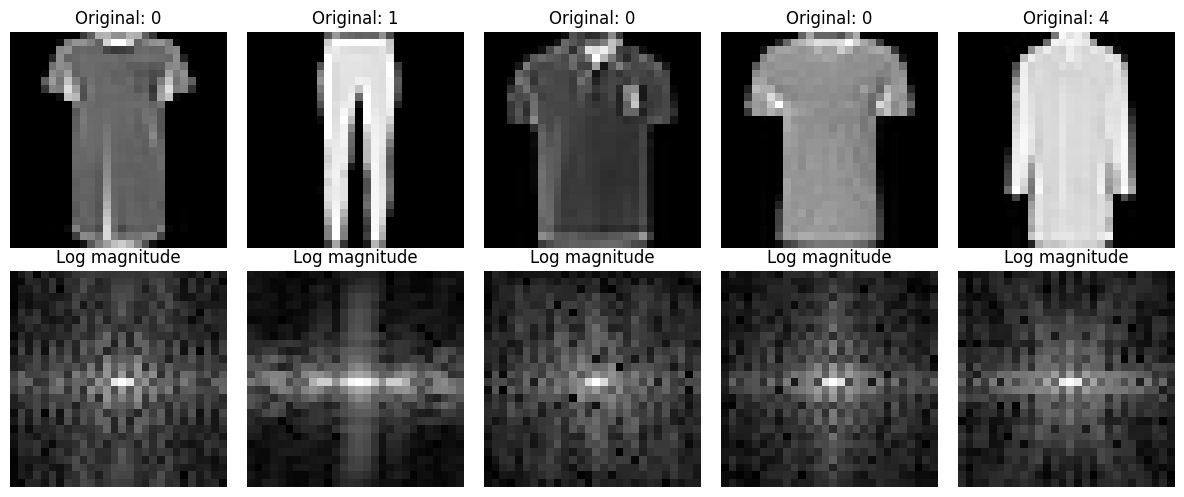

In [6]:
original_images, labels = next(iter(train_loader))
magnitude_images = fourier.log_magnitude(original_images)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i in range(5):
    axes[0, i].imshow(original_images[i, 0], cmap="gray")
    axes[0, i].set_title(f"Original: {labels[i].item()}")
    axes[0, i].axis("off")

    axes[1, i].imshow(magnitude_images[i, 0], cmap="gray")
    axes[1, i].set_title("Log magnitude")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

In [8]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

magnitude_cnn = models.CNN()

magnitude_cnn, magnitude_history = training.fit_model(
    model=magnitude_cnn,
    train_loader=magnitude_train_loader,
    val_loader=magnitude_val_loader,
    epochs=15,
    learning_rate=0.001,
    patience=3,
    min_delta=0.001,
    device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
    )
)

Epoch 01/15 | train loss: 1.1886 | train acc: 55.77% | val loss: 0.7752 | val acc: 73.12%
Epoch 02/15 | train loss: 0.7628 | train acc: 72.60% | val loss: 0.6124 | val acc: 78.22%
Epoch 03/15 | train loss: 0.6556 | train acc: 76.57% | val loss: 0.5403 | val acc: 80.79%
Epoch 04/15 | train loss: 0.5998 | train acc: 78.73% | val loss: 0.5058 | val acc: 81.76%
Epoch 05/15 | train loss: 0.5566 | train acc: 80.02% | val loss: 0.4877 | val acc: 82.66%
Epoch 06/15 | train loss: 0.5300 | train acc: 81.09% | val loss: 0.4680 | val acc: 83.07%
Epoch 07/15 | train loss: 0.5013 | train acc: 82.03% | val loss: 0.4659 | val acc: 82.92%
Epoch 08/15 | train loss: 0.4817 | train acc: 82.55% | val loss: 0.4385 | val acc: 84.17%
Epoch 09/15 | train loss: 0.4629 | train acc: 83.28% | val loss: 0.4406 | val acc: 83.97%
Epoch 10/15 | train loss: 0.4470 | train acc: 83.77% | val loss: 0.4290 | val acc: 84.38%
Epoch 11/15 | train loss: 0.4317 | train acc: 84.28% | val loss: 0.4193 | val acc: 84.68%
Epoch 12/1

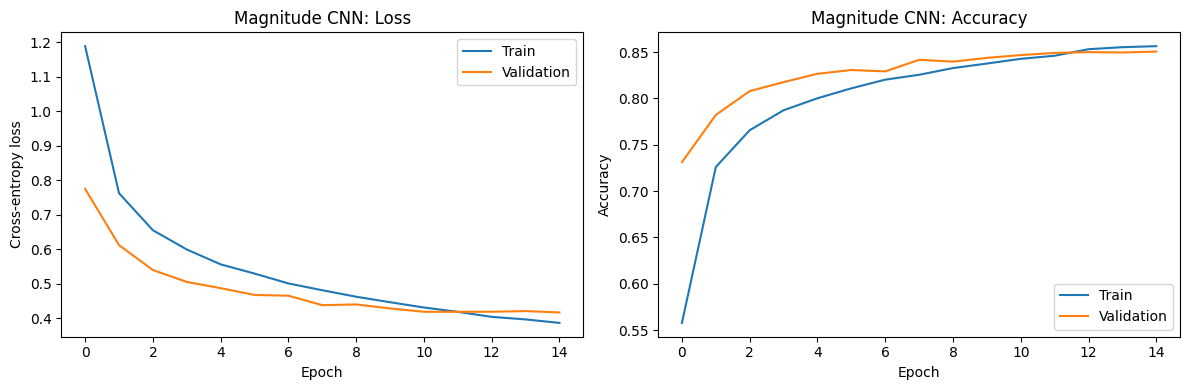

Best epoch: 15
Best validation accuracy: 85.06%


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(magnitude_history["train_loss"], label="Train")
axes[0].plot(magnitude_history["val_loss"], label="Validation")
axes[0].set_title("Magnitude CNN: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

axes[1].plot(magnitude_history["train_accuracy"], label="Train")
axes[1].plot(magnitude_history["val_accuracy"], label="Validation")
axes[1].set_title("Magnitude CNN: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Best epoch:", magnitude_history["best_epoch"])
print(
    "Best validation accuracy:",
    f'{magnitude_history["best_val_accuracy"]:.2%}',
)

In [10]:
test_loader = create_test_loader(
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
)

magnitude_test_loader = fourier.make_magnitude_loader(
    test_loader,
    batch_size=BATCH_SIZE,
)

print("Test examples:", len(magnitude_test_loader.dataset))

Test examples: 10000


In [11]:
from sklearn.metrics import accuracy_score

def evaluate_model(model, loader, device):
    model.eval()
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(labels.numpy())

    accuracy = accuracy_score(all_labels, all_predictions)
    return accuracy, np.array(all_labels), np.array(all_predictions)


magnitude_test_accuracy, y_test, magnitude_predictions = evaluate_model(
    magnitude_cnn,
    magnitude_test_loader,
    device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
    )
)

print(f"Magnitude CNN test accuracy: {magnitude_test_accuracy:.2%}")

Magnitude CNN test accuracy: 85.67%


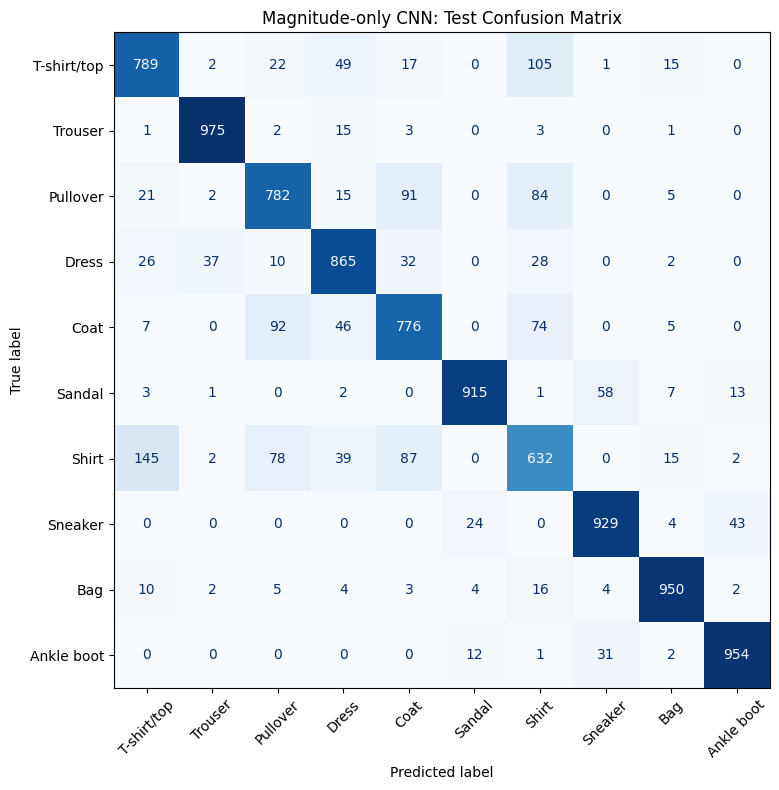

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

cm = confusion_matrix(y_test, magnitude_predictions)

fig, ax = plt.subplots(figsize=(10, 8))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
)
display.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False,
)
ax.set_title("Magnitude-only CNN: Test Confusion Matrix")
plt.tight_layout()
plt.show()

Phase swap experriment

In [16]:
def swap_fourier_phase(image_a, image_b):
    """
    Swap the Fourier phases of two grayscale images.

    Each input has shape (1, 28, 28).
    Returns two reconstructed images with shape (28, 28).
    """
    image_a = image_a.squeeze(0)
    image_b = image_b.squeeze(0)

    spectrum_a = torch.fft.fft2(image_a)
    spectrum_b = torch.fft.fft2(image_b)

    magnitude_a = torch.abs(spectrum_a)
    magnitude_b = torch.abs(spectrum_b)

    phase_a = torch.angle(spectrum_a)
    phase_b = torch.angle(spectrum_b)

    hybrid_a = torch.fft.ifft2(
        magnitude_a * torch.exp(1j * phase_b)
    ).real

    hybrid_b = torch.fft.ifft2(
        magnitude_b * torch.exp(1j * phase_a)
    ).real

    return hybrid_a, hybrid_b

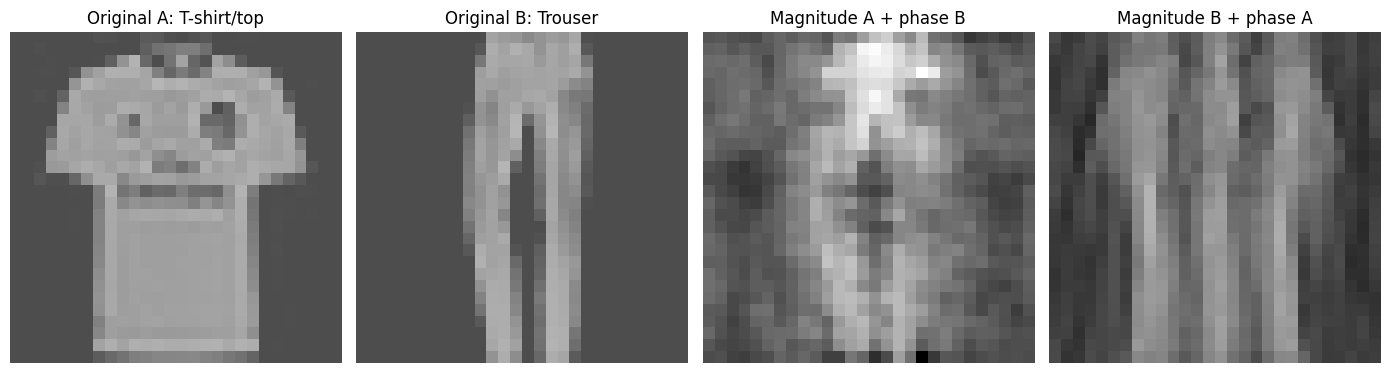

Original A: T-shirt/top
Original B: Trouser


In [17]:
test_images, test_labels = next(iter(test_loader))

# Find one image from each of two different classes.
index_a = 0
index_b = next(
    i for i in range(1, len(test_labels))
    if test_labels[i] != test_labels[index_a]
)

image_a = test_images[index_a]
image_b = test_images[index_b]

hybrid_a, hybrid_b = swap_fourier_phase(image_a, image_b)

names = [
    class_names[test_labels[index_a].item()],
    class_names[test_labels[index_b].item()],
]

images_to_plot = [
    image_a[0].numpy(),
    image_b[0].numpy(),
    hybrid_a.numpy(),
    hybrid_b.numpy(),
]

titles = [
    f"Original A: {names[0]}",
    f"Original B: {names[1]}",
    f"Magnitude A + phase B",
    f"Magnitude B + phase A",
]

# Use one shared intensity scale for a fair visual comparison.
vmin = min(image.min() for image in images_to_plot)
vmax = max(image.max() for image in images_to_plot)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, image, title in zip(axes, images_to_plot, titles):
    ax.imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original A:", names[0])
print("Original B:", names[1])